In [1]:
!pip install -q transformers peft datasets

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
GPU: True


In [7]:
!pip install -q transformers peft datasets

In [8]:
!python -u lab06_starter.py

device: cuda
Loading weights: 100% 272/272 [00:00<00:00, 1134.38it/s]
example prompt: 'Text: i may feel that way but the fact that stories created by adults that are meant for children contain messages that are not so innocent really makes me wonder who exactly is\nEmotion:' answer: ' joy'
zero-shot accuracy (chance 0.167): 0.35
Loading weights: 100% 272/272 [00:00<00:00, 1259.10it/s]
LoRA r=8, 30 steps: accuracy 0.510, trainable 460,800 of 134,975,808, 0.17 s/step


# 1 - Zero-shot baseline and answer-only loss

In [44]:
import lab06_starter as S

model, tok = S.load_model()

train, test, label_ids = S.load_task("emotion", n_train=600, n_test=500, tokenizer=tok)

acc0 = S.evaluate(model, tok, test, label_ids)

print(f"Zero-shot accuracy: {acc0:.3f}")
print(f"Chance accuracy: {1/6:.3f}")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Zero-shot accuracy: 0.326
Chance accuracy: 0.167


In [45]:
def answer_only_labels(input_ids, attention_mask, prompt_lens):
    labels = torch.full_like(input_ids, -100)

    for i in range(len(prompt_lens)):
        labels[i, prompt_lens[i]] = input_ids[i, prompt_lens[i]]

    return labels

In [46]:
ids, mask, plens = S.pad_batch(train[:4], tok.pad_token_id)

labels = answer_only_labels(ids, mask, plens)

# Exactly one position per example is scored
assert torch.all((labels != -100).sum(dim=1) == 1)

# No prompt tokens are scored
for i in range(len(plens)):
    assert torch.all(labels[i, :plens[i]] == -100)

print("Passed")

Passed


# 2 - LoRA from scratch

In [47]:
import torch.nn as nn

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()

        self.base = base
        self.r = r
        self.alpha = alpha
        self.base.requires_grad_(False)

        # Initialize B to zero and A to small random values
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.01)
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * (self.alpha / self.r)


In [48]:
torch.manual_seed(0)

base = nn.Linear(6, 5)
x = torch.randn(3, 6)

original = base(x).detach().clone()
lora = LoRALinear(base, r=2, alpha=4)

# Check identical initial outputs
assert torch.allclose(original, lora(x), atol=1e-6)

# Check trainable parameter count
trainable = sum(p.numel() for p in lora.parameters() if p.requires_grad)
expected = 2 * (6 + 5)

assert trainable == expected

print("Initial match")
print("Trainable parameters:", trainable)

Initial match
Trainable parameters: 22


In [49]:
with torch.no_grad():
    lora.B.copy_(torch.randn_like(lora.B) * 0.01)

merged = nn.Linear(6, 5)

# Merge LoRA weights into the original weights
with torch.no_grad():
    merged.weight.copy_(
        lora.base.weight + (lora.alpha / lora.r) * (lora.B @ lora.A)
    )
    merged.bias.copy_(lora.base.bias)

# Compare outputs
assert torch.allclose(lora(x), merged(x), atol=1e-6)
print("Merged match")

Merged match


In [50]:
from peft import LoraConfig, get_peft_model

# Small model for testing
class SmallModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(6, 5)

    def forward(self, x):
        return self.linear(x)

# Apply PEFT LoRA
config = LoraConfig(
    r=2,
    lora_alpha=4,
    target_modules=["linear"],
    lora_dropout=0.0,
    bias="none"
)

peft_model = get_peft_model(SmallModel(), config)
peft_layer = peft_model.base_model.model.linear

# Copy our weights into PEFT
with torch.no_grad():
    peft_layer.base_layer.weight.copy_(lora.base.weight)
    peft_layer.base_layer.bias.copy_(lora.base.bias)
    peft_layer.lora_A["default"].weight.copy_(lora.A)
    peft_layer.lora_B["default"].weight.copy_(lora.B)

# Compare outputs
assert torch.allclose(lora(x), peft_layer(x), atol=1e-6)

print("PEFT match")

PEFT match


In [51]:
model, tok = S.load_model()
model.eval()
model.requires_grad_(False)

layers = [
    (name, layer)
    for name, layer in model.named_modules()
    if isinstance(layer, nn.Linear)
    and name.split(".")[-1] in ("q_proj", "v_proj")
]

assert len(layers) > 0

# Original model output
sample = torch.tensor(
    [train[0]["prompt_ids"]],
    device=S.DEVICE
)

with torch.no_grad():
    original = model(input_ids=sample).logits

for r in [1, 4, 16]:

    # Replace original layers with our LoRA layers
    for name, layer in layers:
        parent_name, child_name = name.rsplit(".", 1)
        parent = model.get_submodule(parent_name)
        setattr(parent, child_name, LoRALinear(layer, r, 2*r).to(S.DEVICE))

    # Check the whole model is initially unchanged
    with torch.no_grad():
        output = model(input_ids=sample).logits

    assert torch.allclose(original, output, atol=1e-5)

    # Count parameters
    trainable, total = S.count_params(model)

    # Calculate expected parameters using the formula
    expected = sum(
        r * (layer.in_features + layer.out_features)
        for name, layer in layers
    )

    assert trainable == expected

    print(f"Rank {r}:")
    print(f"  Trainable: {trainable:,}")
    print(f"  Percentage: {100 * trainable / total:.4f}%")
    print(f"  Expected: {expected:,}")
    print("  Initial match")

    # Restore original layers for the next rank
    for name, layer in layers:
        parent_name, child_name = name.rsplit(".", 1)
        parent = model.get_submodule(parent_name)
        setattr(parent, child_name, layer)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Rank 1:
  Trainable: 57,600
  Percentage: 0.0428%
  Expected: 57,600
  Initial match
Rank 4:
  Trainable: 230,400
  Percentage: 0.1710%
  Expected: 230,400
  Initial match
Rank 16:
  Trainable: 921,600
  Percentage: 0.6805%
  Expected: 921,600
  Initial match


In [52]:
del model
torch.cuda.empty_cache()

# 3 - Rank sweep against full fine-tuning

In [53]:
seeds = [0, 1, 2]
steps = 120
batch_size = 8

experiments = [
    ("Full", "full", None, 5e-5, answer_only_labels),
    ("LoRA r=1", "lora", 1, 1e-3, answer_only_labels),
    ("LoRA r=4", "lora", 4, 1e-3, answer_only_labels),
    ("LoRA r=16", "lora", 16, 1e-3, answer_only_labels),
    ("LoRA r=16 all-token", "lora", 16, 1e-3, S.all_tokens_labels)
]

In [54]:
import pandas as pd

In [55]:
results = []

for name, mode, r, lr, loss_fn in experiments:
    for seed in seeds:
        print(f"Running {name}, seed {seed}")

        info = S.run(
            mode=mode,
            seed=seed,
            train_examples=train,
            test=test,
            label_ids=label_ids,
            r=r if r is not None else 1,
            steps=steps,
            lr=lr,
            batch_size=batch_size,
            labels_fn=loss_fn
        )

        results.append({
            "method": name,
            "seed": seed,
            "lr": lr,
            **info
        })

        print(f"Accuracy: {info['accuracy']:.3f}")
        print()

Running Full, seed 0


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Accuracy: 0.790

Running Full, seed 1


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Accuracy: 0.788

Running Full, seed 2


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

... (21 outputs left out)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Accuracy: 0.702

Running LoRA r=16 all-token, seed 2


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Accuracy: 0.710



In [56]:
df = pd.DataFrame(results)

table = df.pivot(
    index="method",
    columns="seed",
    values="accuracy"
)

table.columns = ["Seed 0", "Seed 1", "Seed 2"]
table["Mean"] = table.mean(axis=1)

display(table.round(3))

,Seed 0,Seed 1,Seed 2,Mean
method,,,,
Full,0.790,0.788,0.796,0.791
LoRA r=1,0.722,0.716,0.722,0.720
LoRA r=16,0.770,0.764,0.784,0.773
LoRA r=16 all-token,0.716,0.702,0.710,0.709
LoRA r=4,0.764,0.744,0.746,0.751


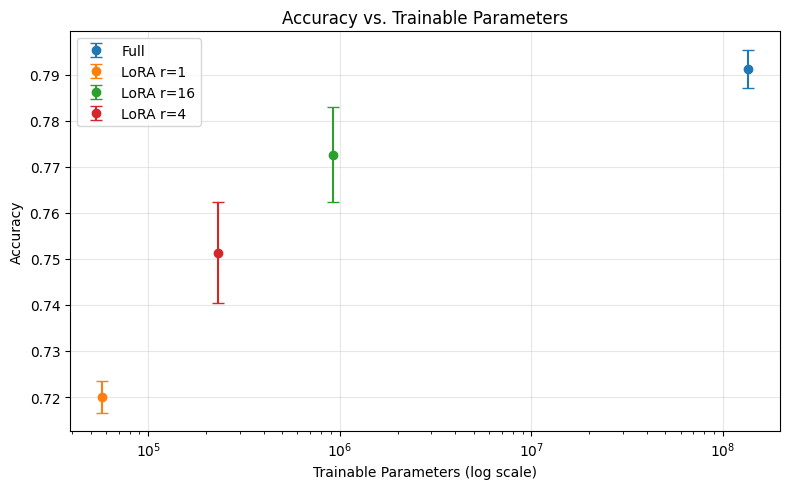

In [57]:
import matplotlib.pyplot as plt

# Exclude the all-token experiment
data = df[df["method"] != "LoRA r=16 all-token"]

# Calculate mean accuracy and standard deviation
summary = data.groupby("method").agg(
    accuracy=("accuracy", "mean"),
    std=("accuracy", "std"),
    trainable=("trainable", "first")
)

plt.figure(figsize=(8, 5))

for method, row in summary.iterrows():
    plt.errorbar(
        row["trainable"],
        row["accuracy"],
        yerr=row["std"],
        fmt="o",
        capsize=4,
        label=method
    )

plt.xscale("log")
plt.xlabel("Trainable Parameters (log scale)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Trainable Parameters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [58]:
print(f"Zero-shot accuracy: {acc0:.3f}")
print(f"Chance accuracy: {1/6:.3f}")

df["zero_shot"] = acc0
df["chance"] = 1/6

display(df[[
    "method", "seed", "accuracy",
    "zero_shot", "chance"
]].round(3))

Zero-shot accuracy: 0.326
Chance accuracy: 0.167


,method,seed,accuracy,zero_shot,chance
0,Full,0,0.790,0.326,0.167
1,Full,1,0.788,0.326,0.167
2,Full,2,0.796,0.326,0.167
3,LoRA r=1,0,0.722,0.326,0.167
4,LoRA r=1,1,0.716,0.326,0.167
5,LoRA r=1,2,0.722,0.326,0.167
6,LoRA r=4,0,0.764,0.326,0.167
7,LoRA r=4,1,0.744,0.326,0.167
8,LoRA r=4,2,0.746,0.326,0.167
9,LoRA r=16,0,0.770,0.326,0.167


In [59]:
df["percentage"] = 100 * df["trainable"] / df["total"]

display(df[[
    "method", "seed", "trainable",
    "total", "percentage"
]].round(4))

,method,seed,trainable,total,percentage
0,Full,0,134515008,134515008,100.0000
1,Full,1,134515008,134515008,100.0000
2,Full,2,134515008,134515008,100.0000
3,LoRA r=1,0,57600,134572608,0.0428
4,LoRA r=1,1,57600,134572608,0.0428
5,LoRA r=1,2,57600,134572608,0.0428
6,LoRA r=4,0,230400,134745408,0.1710
7,LoRA r=4,1,230400,134745408,0.1710
8,LoRA r=4,2,230400,134745408,0.1710
9,LoRA r=16,0,921600,135436608,0.6805


In [61]:
total_seconds = df["seconds"].sum()

print(f"Total training time: {total_seconds / 60:.2f} minutes")
print(f"Total training time: {total_seconds / 3600:.2f} hours")
print(f"Number of runs: {len(df)}")

Total training time: 4.19 minutes
Total training time: 0.07 hours
Number of runs: 15


# 4 - Memory: predict, then measure

In [63]:
# Predict memory in bytes
df["pred_weights"] = 4 * df["total"]
df["pred_gradients"] = 4 * df["trainable"]
df["pred_optimizer"] = 8 * df["trainable"]

df["pred_total"] = (
    df["pred_weights"]
    + df["pred_gradients"]
    + df["pred_optimizer"]
)

# One prediction per method
predictions = df.drop_duplicates("method")

display(predictions[[
    "method",
    "pred_weights",
    "pred_gradients",
    "pred_optimizer",
    "pred_total"
]])

,method,pred_weights,pred_gradients,pred_optimizer,pred_total
0,Full,538060032,538060032,1076120064,2152240128
3,LoRA r=1,538290432,230400,460800,538981632
6,LoRA r=4,538981632,921600,1843200,541746432
9,LoRA r=16,541746432,3686400,7372800,552805632
12,LoRA r=16 all-token,541746432,3686400,7372800,552805632


In [65]:
df["pred_MiB"] = df["pred_total"] / 1024**2
df["measured_MiB"] = df["measured_total"] / 1024**2

display(df[[
    "method",
    "seed",
    "pred_MiB",
    "measured_MiB"
]].round(2))

,method,seed,pred_MiB,measured_MiB
0,Full,0,2052.54,2052.54
1,Full,1,2052.54,2052.54
2,Full,2,2052.54,2052.54
3,LoRA r=1,0,514.01,514.01
4,LoRA r=1,1,514.01,514.01
5,LoRA r=1,2,514.01,514.01
6,LoRA r=4,0,516.65,516.65
7,LoRA r=4,1,516.65,516.65
8,LoRA r=4,2,516.65,516.65
9,LoRA r=16,0,527.20,527.20


In [66]:
df["peak_MiB"] = df["peak_cuda_bytes"] / 1024**2

display(df[[
    "method",
    "seed",
    "pred_MiB",
    "measured_MiB",
    "peak_MiB"
]].round(2))

,method,seed,pred_MiB,measured_MiB,peak_MiB
0,Full,0,2052.54,2052.54,3373.45
1,Full,1,2052.54,2052.54,3369.72
2,Full,2,2052.54,2052.54,3384.06
3,LoRA r=1,0,514.01,514.01,1702.78
4,LoRA r=1,1,514.01,514.01,1689.33
5,LoRA r=1,2,514.01,514.01,1702.78
6,LoRA r=4,0,516.65,516.65,1704.88
7,LoRA r=4,1,516.65,516.65,1691.43
8,LoRA r=4,2,516.65,516.65,1704.88
9,LoRA r=16,0,527.20,527.20,1713.66


In [67]:
memory_table = df[[
    "method",
    "seed",
    "pred_MiB",
    "measured_MiB",
    "peak_MiB"
]].round(2)

print(memory_table.to_markdown(index=False))

| method              |   seed |   pred_MiB |   measured_MiB |   peak_MiB |
|:--------------------|-------:|-----------:|---------------:|-----------:|
| Full                |      0 |    2052.54 |        2052.54 |    3373.45 |
| Full                |      1 |    2052.54 |        2052.54 |    3369.72 |
| Full                |      2 |    2052.54 |        2052.54 |    3384.06 |
| LoRA r=1            |      0 |     514.01 |         514.01 |    1702.78 |
| LoRA r=1            |      1 |     514.01 |         514.01 |    1689.33 |
| LoRA r=1            |      2 |     514.01 |         514.01 |    1702.78 |
| LoRA r=4            |      0 |     516.65 |         516.65 |    1704.88 |
| LoRA r=4            |      1 |     516.65 |         516.65 |    1691.43 |
| LoRA r=4            |      2 |     516.65 |         516.65 |    1704.88 |
| LoRA r=16           |      0 |     527.2  |         527.2  |    1713.66 |
| LoRA r=16           |      1 |     527.2  |         527.2  |    1700.19 |
| LoRA r=16 